# F1 Next-Lap Prediction - ARIMA model

I will investigate now if a more complex model can perform better than the exponential smoothing and look more into the insights of the mode, making it more grey/white box and finally comparing both models and choosing the one for the final application.

To make this comparison plausible and correct, I will make the pipeline the same way as the other model, same splits, inputs and data used, but I will add more features to the model.

## Imports and Loading Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

laps = pd.read_pickle("../data/prepared_race_laps_2022_2025.pkl")

display(
    laps.groupby("Season").agg(
        Races=("RoundNumber", "nunique"),
        LapRecords=("LapNumber", "size"),
        EligiblePairs=("EligiblePair", "sum")
    )
)

print(f"Total eligible pairs: {laps['EligiblePair'].sum():,}")
laps_eligible = laps.loc[laps["EligiblePair"]].copy()

,Races,LapRecords,EligiblePairs
Season,,,
2022,22,23577,16971
2023,22,24420,18902
2024,24,26604,21394
2025,24,26689,20969


Total eligible pairs: 78,236


## Data Split

In [2]:
training_history = laps[laps["Season"] < 2024].copy()
validation_history = laps[laps["Season"] == 2024].copy()
testing_history = laps[laps["Season"] == 2025].copy()

## Preparing uninterrupted lap sequences

I keep laps that are totally clean, in the race-pace, so the sequence will always start over, every time there is an interruption on the race.

In [3]:
keys = ["Season", "RoundNumber", "DriverNumber"]


def prepare_sequences(history):

    usable = (
        history["LapTimeSeconds"].notna()
        & history["IsPitLap"].eq(False)
        & history["TrackStatus"].eq("1")
        & history["IsAccurate"].eq(True)
    )

    sequences = (
        history.loc[usable]
        .sort_values(keys + ["LapNumber"])
        .copy()
    )

    sequences["Segment"] = (
        sequences.groupby(keys)["LapNumber"]
        .diff().ne(1).cumsum()
    )

    sequences["HistoryLaps"] = (
        sequences.groupby("Segment").cumcount() + 1
    )

    return sequences


training_sequences = prepare_sequences(training_history)
validation_sequences = prepare_sequences(validation_history)
testing_sequences = prepare_sequences(testing_history)

print("Usable training laps:", len(training_sequences))
print("Training sequences:", training_sequences["Segment"].nunique())

sequence_lengths = training_sequences.groupby("Segment").size()
display(sequence_lengths.describe().round(1))

prediction_rows = training_sequences.loc[
    training_sequences["EligiblePair"]
].copy()

coverage = pd.DataFrame({
    "MinimumHistory": [5, 10, 15, 20]
})

coverage["PairsWithEnoughHistory"] = [
    prediction_rows["HistoryLaps"].ge(minimum).sum()
    for minimum in coverage["MinimumHistory"]
]

coverage["CoveragePercent"] = (
    100 * coverage["PairsWithEnoughHistory"] / len(prediction_rows)
)

display(coverage.round(1))

Usable training laps: 39312
Training sequences: 3439


count    3439.0
mean       11.4
std         8.7
min         1.0
25%         4.0
50%        10.0
75%        16.0
max        53.0
dtype: float64

,MinimumHistory,PairsWithEnoughHistory,CoveragePercent
0,5,24524,68.4
1,10,14386,40.1
2,15,7488,20.9
3,20,3601,10.0


My training data has 39.312 usable laps across 3.439 uninterrupted sequences. The average in these sequences are 11.4 laps, the median is 10 and the largest sequence contains 53 laps

Only 40.1% have at least ten observations avaliable in this sequence.

While starting the ARIMA model I will need to look into how these affects the model and maybe create fallback systems to make sure the model can understand this smaller patterns

## First ARIMA Model

I begin with a basic ARIMA model using only previous lap times.
External features will be investigated later.

For this first example, I select the longest training sequence and use
its first ten observations to predict the next lap. The actual next-lap
time is used only to evaluate the prediction.

I will compare results with the same-lap baseline and the notebook from 05_timeseriesforecasting

In [4]:
example_segment=sequence_lengths.idxmax()

example = training_sequences.loc[
    training_sequences["Segment"] == example_segment
].sort_values("LapNumber").copy()

display(
    example[["Season", "EventName", "Driver"]].drop_duplicates()
)

history = example["LapTimeSeconds"].iloc[:10].to_numpy()

model=ARIMA(history, order=(1,1,0), trend="n")
fitted=model.fit()

prediction=fitted.forecast(steps=1)[0]
baseline=history[-1]
actual=example["LapTimeSeconds"].iloc[10]

comparison = pd.DataFrame({
    "Model": ["ARIMA", "Same-lap baseline"],
    "Prediction": [prediction, baseline],
    "Actual": [actual, actual],
})

comparison["AbsoluteError"] = (
    comparison["Actual"] - comparison["Prediction"]
).abs()

display(comparison.round(3))

,Season,EventName,Driver
27886,2023,Miami Grand Prix,SAR


,Model,Prediction,Actual,AbsoluteError
0,ARIMA,93.754,93.937,0.183
1,Same-lap baseline,93.681,93.937,0.256


Based on this one prediction, ARIMA got a better value than the same-lap baseline. Now I will look into more detail on different laps and then on the splits to have a final conclusion

## Forecasting

In [5]:
forecasts=[]

for i in range(10,len(example)):
    history=example["LapTimeSeconds"].iloc[:i].to_numpy()

    fitted=ARIMA(history, order=(1,1,0), trend="n").fit()
    prediction=fitted.forecast(steps=1)[0]

    smoothing = (
        pd.Series(history)
        .ewm(alpha=0.9, adjust=False)
        .mean()
        .iloc[-1]
    )

    forecasts.append({
        "LapNumber": example["LapNumber"].iloc[i],
        "Actual": example["LapTimeSeconds"].iloc[i],
        "ARIMA": prediction,
        "Baseline": history[-1],
        "Smoothing": smoothing,
    })

example_forecasts = pd.DataFrame(forecasts)

absolute_errors = (
    example_forecasts[["Baseline", "Smoothing", "ARIMA"]]
    .sub(example_forecasts["Actual"], axis=0)
    .abs()
)

example_forecasts["BestModel"] = absolute_errors.idxmin(axis=1)

display(example_forecasts.head(10).round(3))

,LapNumber,Actual,ARIMA,Baseline,Smoothing,BestModel
0,14.0,93.937,93.754,93.681,93.693,ARIMA
1,15.0,94.223,93.791,93.937,93.913,Baseline
2,16.0,93.748,94.102,94.223,94.192,ARIMA
3,17.0,93.506,94.002,93.748,93.792,Baseline
4,18.0,93.521,93.583,93.506,93.535,Smoothing
5,19.0,93.607,93.516,93.521,93.522,Smoothing
6,20.0,93.574,93.581,93.607,93.599,ARIMA
7,21.0,93.553,93.584,93.574,93.576,Baseline
8,22.0,93.384,93.559,93.553,93.555,Baseline
9,23.0,93.501,93.436,93.384,93.401,ARIMA


Across the 43 evaluated laps, ARIMA had the lowest MAE at 0.3395 seconds, followed by smoothing at 0.3497 and the baseline at 0.3651. ARIMA was also the closest model on 21 laps. These results favour ARIMA for this sequence, but they must be checked across other drivers and races.

In [6]:
closest_counts = (
    example_forecasts["BestModel"]
    .value_counts()
    .reindex(absolute_errors.columns, fill_value=0)
)

example_summary = pd.DataFrame({
    "MAE": absolute_errors.mean(),
    "RMSE": np.sqrt((absolute_errors ** 2).mean()),
    "ClosestLaps": closest_counts,
})

print("Evaluated predictions:", len(example_forecasts))
display(example_summary.sort_values("MAE").round(4))

Evaluated predictions: 43


,MAE,RMSE,ClosestLaps
ARIMA,0.3395,0.5279,21
Smoothing,0.3497,0.5477,8
Baseline,0.3651,0.5695,14


Across these 43 laps, the ARIMA model had a better performance in MAE and RMSE and predicted better 21/43 laps, so this model in this example is already having a better performance than the baseline and the Holt's expontential smoothing model.
Of course, this is for only one race, one driver and a certain sequence, so conclusions can only be taken in the validation and testing splits.

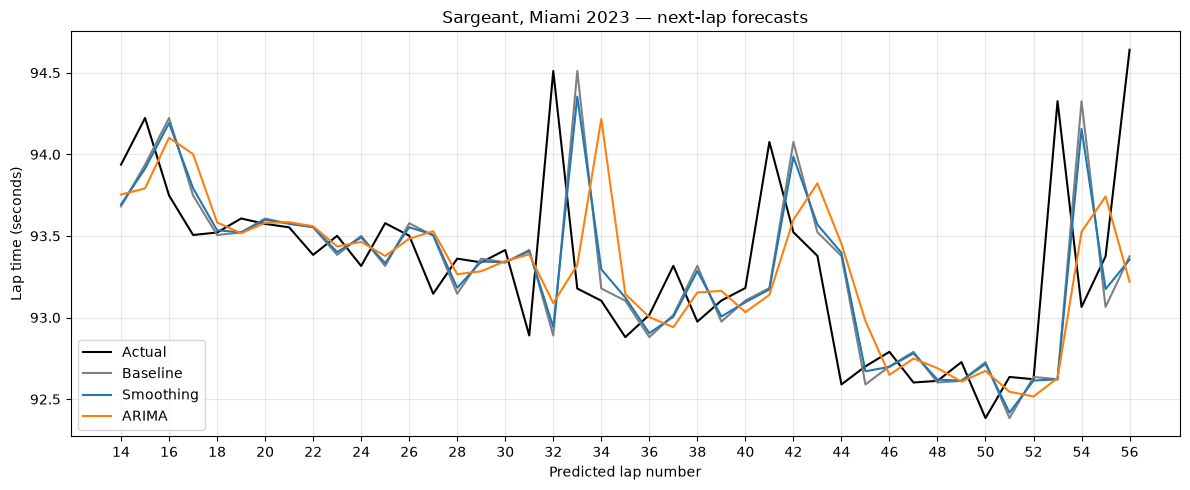

In [7]:
example_forecasts.plot(
    x="LapNumber",
    y=["Actual", "Baseline", "Smoothing", "ARIMA"],
    color=["black", "gray", "tab:blue", "tab:orange"],
    figsize=(12, 5)
)

plt.xlabel("Predicted lap number")
plt.ylabel("Lap time (seconds)")
plt.title("Sargeant, Miami 2023 — next-lap forecasts")
plt.grid(alpha=0.3)
plt.xticks(range(14,57,2))
plt.tight_layout()
plt.show()

The forecasts generally followed the lap-time evolution, but all methods struggled with sudden changes. The baseline repeats the previous lap time, while smoothing behaves similarly because it gives high weight to the latest observation.

ARIMA sometimes predicted a reversal successfully, but also made incorrect corrections. This plot does not identify the causes of the sudden changes.

## Fallback system of the model

In [8]:
def forecast_arima(history, min_history=10):

    baseline = history[-1]

    if len(history) < min_history:
        return baseline, "Baseline: short history"

    try:
        fitted = ARIMA(history, order=(1, 1, 0), trend="n").fit()
        prediction = fitted.forecast(steps=1)[0]

        if fitted.mle_retvals.get("converged", False) and np.isfinite(prediction):
            return prediction, "ARIMA"

    except (ValueError, np.linalg.LinAlgError):
        return baseline, "Baseline: fit failed"

    return baseline, "Baseline: unreliable fit"

## Forecasting in the Training Split

In [9]:
training_forecasts = training_sequences.copy()

training_forecasts["Baseline"] = training_forecasts["LapTimeSeconds"]
training_forecasts["ARIMA"] = np.nan
training_forecasts["Smoothing"] = np.nan
training_forecasts["Method"] = ""

segments = training_sequences.groupby("Segment")

for number, (_, sequence) in enumerate(segments, start=1):

    times = sequence["LapTimeSeconds"].to_numpy()
    training_forecasts.loc[sequence.index, "Smoothing"] = (
        sequence["LapTimeSeconds"]
        .ewm(alpha=0.9, adjust=False)
        .mean()
    )

    for i, row_index in enumerate(sequence.index):

        history = times[:i + 1]

        prediction, method = forecast_arima(history)

        training_forecasts.loc[row_index, "ARIMA"] = prediction
        training_forecasts.loc[row_index, "Method"] = method

    if number % 500 == 0:
        print(f"Processed {number} / {segments.ngroups} sequences")

training_errors = training_forecasts.loc[
    training_forecasts["EligiblePair"]
].copy()

print("Evaluated training pairs:", len(training_errors))
display(training_errors["Method"].value_counts())

c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = supe

Processed 500 / 3439 sequences


c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.star

Processed 1000 / 3439 sequences


c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters fou

Processed 1500 / 3439 sequences


... (5 outputs left out)

Processed 3000 / 3439 sequences


c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = supe

Evaluated training pairs: 35873


Method
Baseline: short history     21487
ARIMA                       14289
Baseline: unreliable fit       97
Name: count, dtype: int64

## Training Evaluation

In [10]:
evaluation = training_errors.loc[
    training_errors["Method"] == "ARIMA"
].copy()

actual = evaluation["NextLapTimeSeconds"]
scores = []

for name in ["Baseline", "Smoothing", "ARIMA"]:

    predictions = evaluation[name]

    scores.append({
        "Model": name,
        "MAE": mean_absolute_error(actual, predictions),
        "RMSE": np.sqrt(mean_squared_error(actual, predictions)),
        "R2": r2_score(actual, predictions),
    })

training_comparison = pd.DataFrame(scores).sort_values("MAE")

coverage = 100 * len(evaluation) / len(training_errors)

print("Evaluated pairs:", len(evaluation))
print(f"Coverage: {coverage:.1f}%")

display(training_comparison.round(4))

Evaluated pairs: 14289
Coverage: 39.8%


,Model,MAE,RMSE,R2
1,Smoothing,0.3668,0.6774,0.9960
0,Baseline,0.3758,0.6876,0.9958
2,ARIMA,0.3852,0.6907,0.9958


On the evaluated training laps, smoothing achieved the lowest MAE, followed by the baseline and ARIMA. The initial ARIMA configuration did not improve forecasting accuracy. This comparison includes only successful ARIMA predictions, covering 39.8% of eligible training pairs.

## Forecasting Validation and Evaluation

In [11]:
validation_forecasts = validation_sequences.copy()

validation_forecasts["Baseline"] = validation_forecasts["LapTimeSeconds"]
validation_forecasts["ARIMA"] = np.nan
validation_forecasts["Smoothing"] = np.nan
validation_forecasts["Method"] = ""

segments = validation_sequences.groupby("Segment")

for number, (_, sequence) in enumerate(segments, start=1):

    times = sequence["LapTimeSeconds"].to_numpy()

    validation_forecasts.loc[sequence.index, "Smoothing"] = (
        sequence["LapTimeSeconds"]
        .ewm(alpha=0.9, adjust=False)
        .mean()
    )

    for i, row_index in enumerate(sequence.index):

        history = times[:i + 1]

        prediction, method = forecast_arima(history)

        validation_forecasts.loc[row_index, "ARIMA"] = prediction
        validation_forecasts.loc[row_index, "Method"] = method

    if number % 500 == 0:
        print(f"Processed {number} / {segments.ngroups} sequences")

validation_errors = validation_forecasts.loc[
    validation_forecasts["EligiblePair"]
].copy()

print("Evaluated validation pairs:", len(validation_errors))
display(validation_errors["Method"].value_counts())


validation_evaluation = validation_errors.loc[
    validation_errors["Method"] == "ARIMA"
].copy()

actual = validation_evaluation["NextLapTimeSeconds"]
scores = []

for name in ["Baseline", "Smoothing", "ARIMA"]:

    predictions = validation_evaluation[name]

    scores.append({
        "Model": name,
        "MAE": mean_absolute_error(actual, predictions),
        "RMSE": np.sqrt(mean_squared_error(actual, predictions)),
        "R2": r2_score(actual, predictions),
    })

validation_comparison = pd.DataFrame(scores).sort_values("MAE")

validation_coverage = (
    100 * len(validation_evaluation) / len(validation_errors)
)

print("Evaluated pairs with ARIMA:", len(validation_evaluation))
print(f"Coverage: {validation_coverage:.1f}%")

display(validation_comparison.round(4))

c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = supe

Processed 500 / 1605 sequences


c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary start

Processed 1000 / 1605 sequences


c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = supe

Processed 1500 / 1605 sequences


c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Francisco\Deskt

Evaluated validation pairs: 21394


Method
Baseline: short history     10939
ARIMA                       10406
Baseline: unreliable fit       49
Name: count, dtype: int64

Evaluated pairs with ARIMA: 10406
Coverage: 48.6%


,Model,MAE,RMSE,R2
1,Smoothing,0.4355,0.8561,0.9922
0,Baseline,0.4447,0.8752,0.9919
2,ARIMA,0.4614,0.9637,0.9901


## Validation Errors

In [12]:
history_analysis = validation_evaluation.copy()

history_analysis["HistoryGroup"] = pd.cut(
    history_analysis["HistoryLaps"],
    bins=[9, 14, 19, 29, np.inf],
    labels=["10-14", "15-19", "20-29", "30+"]
)
for name in ["Baseline", "Smoothing", "ARIMA"]:
    history_analysis[f"{name}Error"] = (
        history_analysis[name]
        - history_analysis["NextLapTimeSeconds"]
    ).abs()

history_comparison = (
    history_analysis.groupby("HistoryGroup", observed=True)
    .agg(
        Predictions=("ARIMAError", "size"),
        BaselineMAE=("BaselineError", "mean"),
        SmoothingMAE=("SmoothingError", "mean"),
        ARIMAMAE=("ARIMAError", "mean")
    )
)

history_comparison["ARIMA_vs_Smoothing"] = (
    history_comparison["ARIMAMAE"]
    - history_comparison["SmoothingMAE"]
)

display(history_comparison.round(4))

,Predictions,BaselineMAE,SmoothingMAE,ARIMAMAE,ARIMA_vs_Smoothing
HistoryGroup,,,,,
10-14,4021,0.3836,0.3748,0.3933,0.0185
15-19,2784,0.4788,0.4690,0.5301,0.0611
20-29,2535,0.4654,0.4588,0.4665,0.0077
30+,1066,0.5369,0.5211,0.5270,0.0059


ARIMAl in the validation split, has worse MAE results compared to all models, but after having more than 30 laps it performs better than the baseline

## ARIMA Hyperparameter Tuning
Since, the results I got in the validation split, were quite underwhelming, I am now looking more into detail of the model to improve it. I will start by using Optuna to find out the best possible combinations for the model.

In [13]:
import optuna

eligible = validation_sequences.loc[
    validation_sequences["EligiblePair"]
]

tuning_rows = pd.concat([
    race.sample(n=min(100, len(race)), random_state=42)
    for _, race in eligible.groupby("RoundNumber")
])

tuning_cases = []

for _, row in tuning_rows.iterrows():
    history = validation_sequences.loc[
        validation_sequences["Segment"].eq(row["Segment"])
        & validation_sequences["LapNumber"].le(row["LapNumber"])
    ].sort_values("LapNumber")["LapTimeSeconds"].to_numpy()

    tuning_cases.append((history, row["NextLapTimeSeconds"]))

actual_values = pd.Series([
    actual for history, actual in tuning_cases
])

trial_predictions = {}


def objective(trial):
    p = trial.suggest_int("p", 0, 1)
    d = trial.suggest_int("d", 0, 1)
    q = trial.suggest_int("q", 0, 1)
    linear_trend = trial.suggest_categorical(
        "linear_trend", [False, True]
    )

    if d == 0:
        trend = "ct" if linear_trend else "c"
    else:
        trend = "t" if linear_trend else "n"

    predictions = []
    successful_fits = 0

    for history, actual in tuning_cases:
        prediction = history[-1]

        if len(history) >= 10:
            try:
                fitted = ARIMA(
                    history, order=(p, d, q), trend=trend
                ).fit()

                forecast = fitted.forecast(steps=1)[0]

                if (
                    fitted.mle_retvals.get("converged", False)
                    and np.isfinite(forecast)
                ):
                    prediction = forecast
                    successful_fits += 1

            except (ValueError, np.linalg.LinAlgError):
                pass

        predictions.append(prediction)

    trial_predictions[trial.number] = predictions
    trial.set_user_attr("trend", trend)
    trial.set_user_attr(
        "coverage", 100 * successful_fits / len(tuning_cases)
    )

    return mean_absolute_error(actual_values, predictions)


search_space = {
    "p": [0, 1],
    "d": [0, 1],
    "q": [0, 1],
    "linear_trend": [False, True]
}

study = optuna.create_study(
    direction="minimize",
    sampler=optuna.samplers.GridSampler(search_space, seed=42)
)

study.optimize(objective, n_trials=16)

tuning_results = study.trials_dataframe()
tuning_results["MAE"] = tuning_results["value"]
tuning_results["CoveragePercent"] = tuning_results["user_attrs_coverage"]

common_cases = pd.Series(True, index=actual_values.index)

print("Sampled pairs:", len(tuning_cases))
print("Validation races:", tuning_rows["RoundNumber"].nunique())
print("MAE includes fallbacks; coverage shows successful ARIMA use.")

display(
    tuning_results[
        [
            "params_p",
            "params_d",
            "params_q",
            "user_attrs_trend",
            "MAE",
            "CoveragePercent"
        ]
    ].sort_values("MAE").round(4)
)

c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[I 2026-10-29 10:58:14,589] A new study created in memory with name: no-name-c308aae8-107c-49c1-b4cd-bd84d441d83a
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\state

Sampled pairs: 2400
Validation races: 24
MAE includes fallbacks; coverage shows successful ARIMA use.


,params_p,params_d,params_q,user_attrs_trend,MAE,CoveragePercent
6,0,1,0,n,0.4427,45.4583
7,0,1,1,n,0.4440,46.0000
12,1,1,0,n,0.4472,45.8750
5,1,1,1,n,0.4500,45.7083
8,1,0,0,c,0.4537,46.0833
13,0,1,0,t,0.4541,45.2083
3,1,1,0,t,0.4589,45.9167
11,1,0,1,ct,0.4594,31.7083
9,1,1,1,t,0.4617,44.7500
14,1,0,1,c,0.4618,43.4583


I will select the second best configuration, as the first one follows the same rules as the baseline.

The second best configuration uses the latest lap time and adds a correction based on the most recent estimated prediction error. The difference between the prediction and the real times is adjusted every lap to get better predictions.


In [14]:
selected = tuning_results.loc[
    tuning_results["params_p"].eq(0)
    & tuning_results["params_d"].eq(1)
    & tuning_results["params_q"].eq(1)
    & tuning_results["user_attrs_trend"].eq("n")
].iloc[0]

baseline_predictions = [
    history[-1]
    for history, actual in tuning_cases
]

smoothing_predictions = [
    pd.Series(history).ewm(alpha=0.9, adjust=False).mean().iloc[-1]
    for history, actual in tuning_cases
]

sample_comparison = pd.DataFrame({
    "Model": ["Baseline", "Smoothing", "ARIMA(0,1,1) + fallback"],
    "MAE": [
        mean_absolute_error(actual_values, baseline_predictions),
        mean_absolute_error(actual_values, smoothing_predictions),
        selected["MAE"]
    ]
}).sort_values("MAE")

print("Selected configuration: ARIMA(0,1,1)")
print("Trend:", selected["user_attrs_trend"])
print("Compared cases:", len(tuning_cases))

display(sample_comparison.round(4))

Selected configuration: ARIMA(0,1,1)
Trend: n
Compared cases: 2400


,Model,MAE
1,Smoothing,0.4381
0,Baseline,0.4427
2,"ARIMA(0,1,1) + fallback",0.4440


On 2400 sampled pairs across 24 validation races, the tuned ARIMA model achieved a MAE of 0.444 seconds. It is still worse than the baseline and the smoothing model, but I will investigate more to understand what can be improved.

## Tuned Validation Split

In [15]:
tuned_validation = validation_forecasts.loc[
    validation_forecasts["EligiblePair"]
].copy()

tuned_validation["TunedARIMA"] = tuned_validation["Baseline"]
successful_fits = 0

segments = validation_sequences.groupby("Segment")

for number, (_, sequence) in enumerate(segments, start=1):
    sequence = sequence.sort_values("LapNumber")
    times = sequence["LapTimeSeconds"].to_numpy()

    for i in range(9, len(times)):
        if not sequence["EligiblePair"].iloc[i]:
            continue

        try:
            fitted = ARIMA(
                times[:i + 1],
                order=(0, 1, 1),
                trend="n"
            ).fit()

            prediction = fitted.forecast(steps=1)[0]

            if (
                fitted.mle_retvals.get("converged", False)
                and np.isfinite(prediction)
            ):
                row_index = sequence.index[i]
                tuned_validation.at[row_index, "TunedARIMA"] = prediction
                successful_fits += 1

        except (ValueError, np.linalg.LinAlgError):
            continue

    if number % 200 == 0:
        print(f"Processed {number} / {segments.ngroups} sequences")

actual = tuned_validation["NextLapTimeSeconds"]
scores = []

for name in ["Baseline", "Smoothing", "ARIMA", "TunedARIMA"]:
    predictions = tuned_validation[name]

    scores.append({
        "Model": name,
        "MAE": mean_absolute_error(actual, predictions),
        "RMSE": np.sqrt(mean_squared_error(actual, predictions)),
        "R2": r2_score(actual, predictions)
    })

tuned_validation_comparison = pd.DataFrame(scores).sort_values("MAE")

print("Selected configuration: ARIMA(0,1,1), no trend")
print("Compared pairs:", len(tuned_validation))
print("Scores include fallback predictions.")
print(
    "Successful ARIMA use:",
    f"{100 * successful_fits / len(tuned_validation):.1f}%"
)

display(tuned_validation_comparison.round(4))

c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = 

Processed 200 / 1605 sequences


c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros

Processed 400 / 1605 sequences


c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlef

Processed 600 / 1605 sequences


... (7 outputs left out)

Processed 1400 / 1605 sequences


c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros

Processed 1600 / 1605 sequences
Selected configuration: ARIMA(0,1,1), no trend
Compared pairs: 21394
Scores include fallback predictions.
Successful ARIMA use: 48.6%


,Model,MAE,RMSE,R2
1,Smoothing,0.4601,1.0432,0.9893
0,Baseline,0.4645,1.0512,0.9891
3,TunedARIMA,0.4690,1.0592,0.9890
2,ARIMA,0.4726,1.0882,0.9884


## Comparing Forecasts (Visualization)

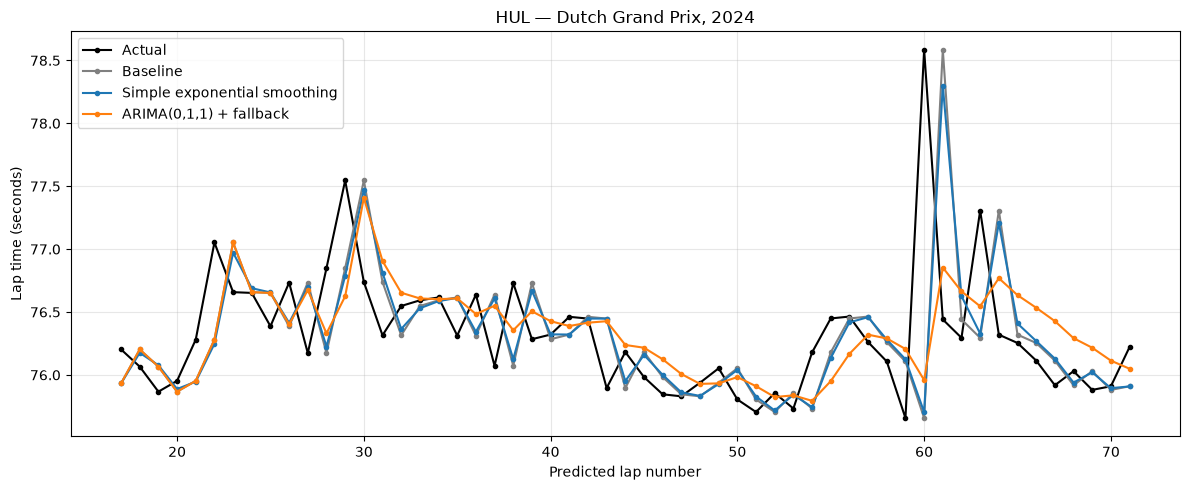

Compared pairs: 55


,Model,MAE
2,TunedARIMA,0.3393
1,Smoothing,0.3646
0,Baseline,0.3737


In [16]:
segment = tuned_validation.groupby("Segment").size().idxmax()

example = tuned_validation.loc[
    tuned_validation["Segment"].eq(segment)
].sort_values("LapNumber").copy()

example["PredictedLap"] = example["LapNumber"] + 1

race = example["EventName"].iloc[0]
driver = example["Driver"].iloc[0]

example.plot(
    x="PredictedLap",
    y=["NextLapTimeSeconds", "Baseline", "Smoothing", "TunedARIMA"],
    color=["black", "gray", "tab:blue", "tab:orange"],
    figsize=(12, 5),
    marker="."
)

plt.legend([
    "Actual",
    "Baseline",
    "Simple exponential smoothing",
    "ARIMA(0,1,1) + fallback"
])
plt.xlabel("Predicted lap number")
plt.ylabel("Lap time (seconds)")
plt.title(f"{driver} — {race}, 2024")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

scores = []

for name in ["Baseline", "Smoothing", "TunedARIMA"]:
    scores.append({
        "Model": name,
        "MAE": mean_absolute_error(
            example["NextLapTimeSeconds"],
            example[name]
        )
    })

print("Compared pairs:", len(example))
display(pd.DataFrame(scores).sort_values("MAE").round(4))

The models follow lap-time patterns but struggle with sudden changes. ARIMA’s corrections sometimes improve predictions, but smoothing performs better overall.

## Saving Results

Running the whole notebook takes quite a long time and I need to save the models and re-use them to avoid repeating this process all the time.

In [17]:
pd.to_pickle({
    "training_forecasts": training_forecasts,
    "validation_forecasts": validation_forecasts,
    "tuned_validation": tuned_validation,
    "tuning_results": tuning_results,
    "trial_predictions": trial_predictions,
    "tuning_cases": tuning_cases
}, "../data/arima_results.pkl")

print("Results saved.")

Results saved.


In [18]:
saved = pd.read_pickle("../data/arima_results.pkl")

training_forecasts = saved["training_forecasts"]
validation_forecasts = saved["validation_forecasts"]
tuned_validation = saved["tuned_validation"]
tuning_results = saved["tuning_results"]
trial_predictions = saved["trial_predictions"]
tuning_cases = saved["tuning_cases"]

actual_values = pd.Series([
    actual for history, actual in tuning_cases
])

common_cases = pd.DataFrame(trial_predictions).notna().all(axis=1)

print("Results loaded.")

Results loaded.


## Final Test Evaluation

In [19]:
def forecast_arima(history, min_history=10, order=(1, 1, 0)):
    baseline = history[-1]

    if len(history) < min_history:
        return baseline, "Baseline: short history"

    try:
        fitted = ARIMA(history, order=order, trend="n").fit()
        prediction = fitted.forecast(steps=1)[0]

        if (
            fitted.mle_retvals.get("converged", False)
            and np.isfinite(prediction)
        ):
            return prediction, "ARIMA"

    except (ValueError, np.linalg.LinAlgError):
        return baseline, "Baseline: fit failed"

    return baseline, "Baseline: unreliable fit"


testing_forecasts = testing_sequences.copy()

testing_forecasts["Baseline"] = testing_forecasts["LapTimeSeconds"]
testing_forecasts["Smoothing"] = np.nan
testing_forecasts["ARIMA"] = np.nan
testing_forecasts["Method"] = ""

segments = testing_sequences.groupby("Segment")

for number, (_, sequence) in enumerate(segments, start=1):
    sequence = sequence.sort_values("LapNumber")
    times = sequence["LapTimeSeconds"].to_numpy()

    testing_forecasts.loc[sequence.index, "Smoothing"] = (
        sequence["LapTimeSeconds"].ewm(alpha=0.9, adjust=False).mean()
    )

    for i, row_index in enumerate(sequence.index):
        if not sequence["EligiblePair"].iloc[i]:
            continue

        prediction, method = forecast_arima(
            times[:i + 1],
            order=(0, 1, 1)
        )

        testing_forecasts.at[row_index, "ARIMA"] = prediction
        testing_forecasts.at[row_index, "Method"] = method

    if number % 200 == 0:
        print(f"Processed {number} / {segments.ngroups} sequences")

testing_forecasts.to_pickle("../data/arima_test_forecasts.pkl")

testing_errors = testing_forecasts.loc[
    testing_forecasts["EligiblePair"]
].copy()

testing_evaluation = testing_errors.copy()

actual = testing_evaluation["NextLapTimeSeconds"]
scores = []

for name in ["Baseline", "Smoothing", "ARIMA"]:
    predictions = testing_evaluation[name]

    scores.append({
        "Model": name,
        "MAE": mean_absolute_error(actual, predictions),
        "RMSE": np.sqrt(mean_squared_error(actual, predictions)),
        "R2": r2_score(actual, predictions)
    })

testing_comparison = pd.DataFrame(scores).sort_values("MAE")

coverage = 100 * testing_errors["Method"].eq("ARIMA").mean()

print("Test configuration: ARIMA(0,1,1), no trend")
print("Compared pairs:", len(testing_evaluation))
print(f"Successful ARIMA use: {coverage:.1f}%")
print("Scores include fallback predictions.")

display(testing_errors["Method"].value_counts())
display(testing_comparison.round(4))

c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros

Processed 200 / 1540 sequences


c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros

Processed 400 / 1540 sequences


c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlef

Processed 600 / 1540 sequences


... (8 outputs left out)

c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\Francisco\Desktop\Work\Semester 3\Practice Challenge\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = 

Test configuration: ARIMA(0,1,1), no trend
Compared pairs: 20969
Successful ARIMA use: 50.1%
Scores include fallback predictions.


Method
ARIMA                       10498
Baseline: short history     10401
Baseline: unreliable fit       70
Name: count, dtype: int64

,Model,MAE,RMSE,R2
1,Smoothing,0.3807,0.6677,0.9959
0,Baseline,0.3855,0.6812,0.9957
2,ARIMA,0.3900,0.6890,0.9956


## Models Performance

In [21]:
race_errors = testing_errors.copy()

for name in ["Baseline", "Smoothing", "ARIMA"]:
    race_errors[f"{name}Error"] = (
        race_errors[name] - race_errors["NextLapTimeSeconds"]
    ).abs()

race_comparison = (
    race_errors.groupby(["RoundNumber", "EventName"])
    .agg(
        Pairs=("NextLapTimeSeconds", "size"),
        BaselineMAE=("BaselineError", "mean"),
        SmoothingMAE=("SmoothingError", "mean"),
        ARIMAMAE=("ARIMAError", "mean")
    )
)

race_comparison["ARIMA_vs_Baseline"] = (
    race_comparison["BaselineMAE"] - race_comparison["ARIMAMAE"]
)

race_comparison["ARIMA_vs_Smoothing"] = (
    race_comparison["SmoothingMAE"] - race_comparison["ARIMAMAE"]
)

display(race_comparison.round(4))

print(
    "Races where ARIMA beats the baseline:",
    race_comparison["ARIMA_vs_Baseline"].gt(0).sum(),
    "/",
    len(race_comparison)
)

print(
    "Races where ARIMA beats smoothing:",
    race_comparison["ARIMA_vs_Smoothing"].gt(0).sum(),
    "/",
    len(race_comparison)
)

print(
    "Races where smoothing beats the baseline:",
    race_comparison["SmoothingMAE"].lt(race_comparison["BaselineMAE"]).sum(),
    "/",
    len(race_comparison)
)


,,Pairs,BaselineMAE,SmoothingMAE,ARIMAMAE,ARIMA_vs_Baseline,ARIMA_vs_Smoothing
RoundNumber,EventName,,,,,,
1,Australian Grand Prix,494,0.7748,0.8059,0.8314,-0.0566,-0.0255
2,Chinese Grand Prix,876,0.3094,0.3059,0.3106,-0.0012,-0.0047
3,Japanese Grand Prix,956,0.2667,0.2612,0.2775,-0.0107,-0.0163
4,Bahrain Grand Prix,885,0.3806,0.3697,0.3838,-0.0032,-0.0141
5,Saudi Arabian Grand Prix,776,0.3557,0.3524,0.3758,-0.0201,-0.0234
6,Miami Grand Prix,800,0.2927,0.2868,0.3025,-0.0098,-0.0157
7,Emilia Romagna Grand Prix,875,0.3863,0.3790,0.3928,-0.0065,-0.0138
8,Monaco Grand Prix,1088,0.6644,0.6573,0.6815,-0.0171,-0.0241
9,Spanish Grand Prix,914,0.4364,0.4317,0.4429,-0.0065,-0.0112


Races where ARIMA beats the baseline: 5 / 24
Races where ARIMA beats smoothing: 2 / 24
Races where smoothing beats the baseline: 21 / 24


This race-level comparison uses the 2025 test data, including fallback predictions. Positive values in ARIMA_vs_Baseline and ARIMA_vs_Smoothing indicate lower MAE for ARIMA. The printed counts show how often ARIMA outperforms the baseline and smoothing, and how often smoothing outperforms the baseline across the test races.

## Final Conclusions

On the 2025 test set, simple exponential smoothing achieved the lowest MAE at 0.3807 seconds, followed by the baseline at 0.3855 seconds and ARIMA (0,1,1) at 0.3900 seconds. All models were compared on the same 20,969 eligible pairs, including fallback predictions.

ARIMA successfully generated forecasts for 50.1% of eligible pairs. For the remaining cases, it used the latest lap time as a fallback, mainly because fewer than ten uninterrupted observations were available.

The grid search ranked ARIMA (0,1,0), which follows the baseline forecasting rule, first. I investigated the second-ranked configuration, ARIMA (0,1,1), because it adjusts forecasts using the latest estimated error. Although it improved on the original ARIMA (1,1,0) on the full validation set, it did not outperform the baseline or smoothing.

The improvement observed in the initial single-driver example did not generalise to the broader evaluation. Among the methods tested, simple exponential smoothing therefore remains the preferred approach for this next-lap prediction task.